# Supplementary: CDR efficiency by region vs. application flux

Cumulative CDR through 2100 as a fraction of each GCAM region's target at a single dust radius. Marginal histograms show where each region's curve peaks: application flux (top) and peak efficiency (right).

In [16]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

S3_RUN = ("s3://carbonplan-carbon-removal/ew-workflows-data/scepter/postprocessed/gcam/"
          "gcam_opr_full2_cec1/exe_central1p5_001_multiSchedule/exe_central1p5")
dssum = xr.open_zarr(os.path.join(S3_RUN, "ds_cdr_globalScaling_constApp_SUM.zarr"))

DUSTRAD    = 0.2
CEC_FACTOR = float(dssum.cec_factor.values[0])
APPRATE_MIN, APPRATE_MAX = 0.25, 50
XLIM, YLIM = (APPRATE_MIN, 30), None

COLOR, ALPHA, LW = "#1b3a4b", 0.45, 1.2
TARGET_COLOR     = "#898781"
HIST_BINS        = 15
TOP_BAR_DEX      = 0.075   # top-histogram bar width (log10 units)

SAVE_ON  = True
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
savehere = REPO / "figures/supp/panels"
savehere.mkdir(parents=True, exist_ok=True)

FS_LAB, FS_TICK = 13, 11

In [17]:
sel = dict(dustrad=DUSTRAD, cec_factor=CEC_FACTOR, apprate_base=slice(APPRATE_MIN, APPRATE_MAX))
target = dssum["gcam_cdr"].sel(**sel).sum("time").mean("apprate_base")
eff = (dssum["cdr_adv_region"].sel(**sel).sum("time") / target).compute()   # (apprate_base, site)

peak_eff  = eff.max("apprate_base")
peak_rate = eff.idxmax("apprate_base")
print(f"peak efficiency: median={float(peak_eff.median()):.2f} [{float(peak_eff.min()):.2f}-{float(peak_eff.max()):.2f}]")
print(f"peak flux (t/ha/yr): median={float(peak_rate.median()):g} [{float(peak_rate.min()):g}-{float(peak_rate.max()):g}]")

peak efficiency: median=0.68 [0.39-0.82]
peak flux (t/ha/yr): median=2.5 [1-10]


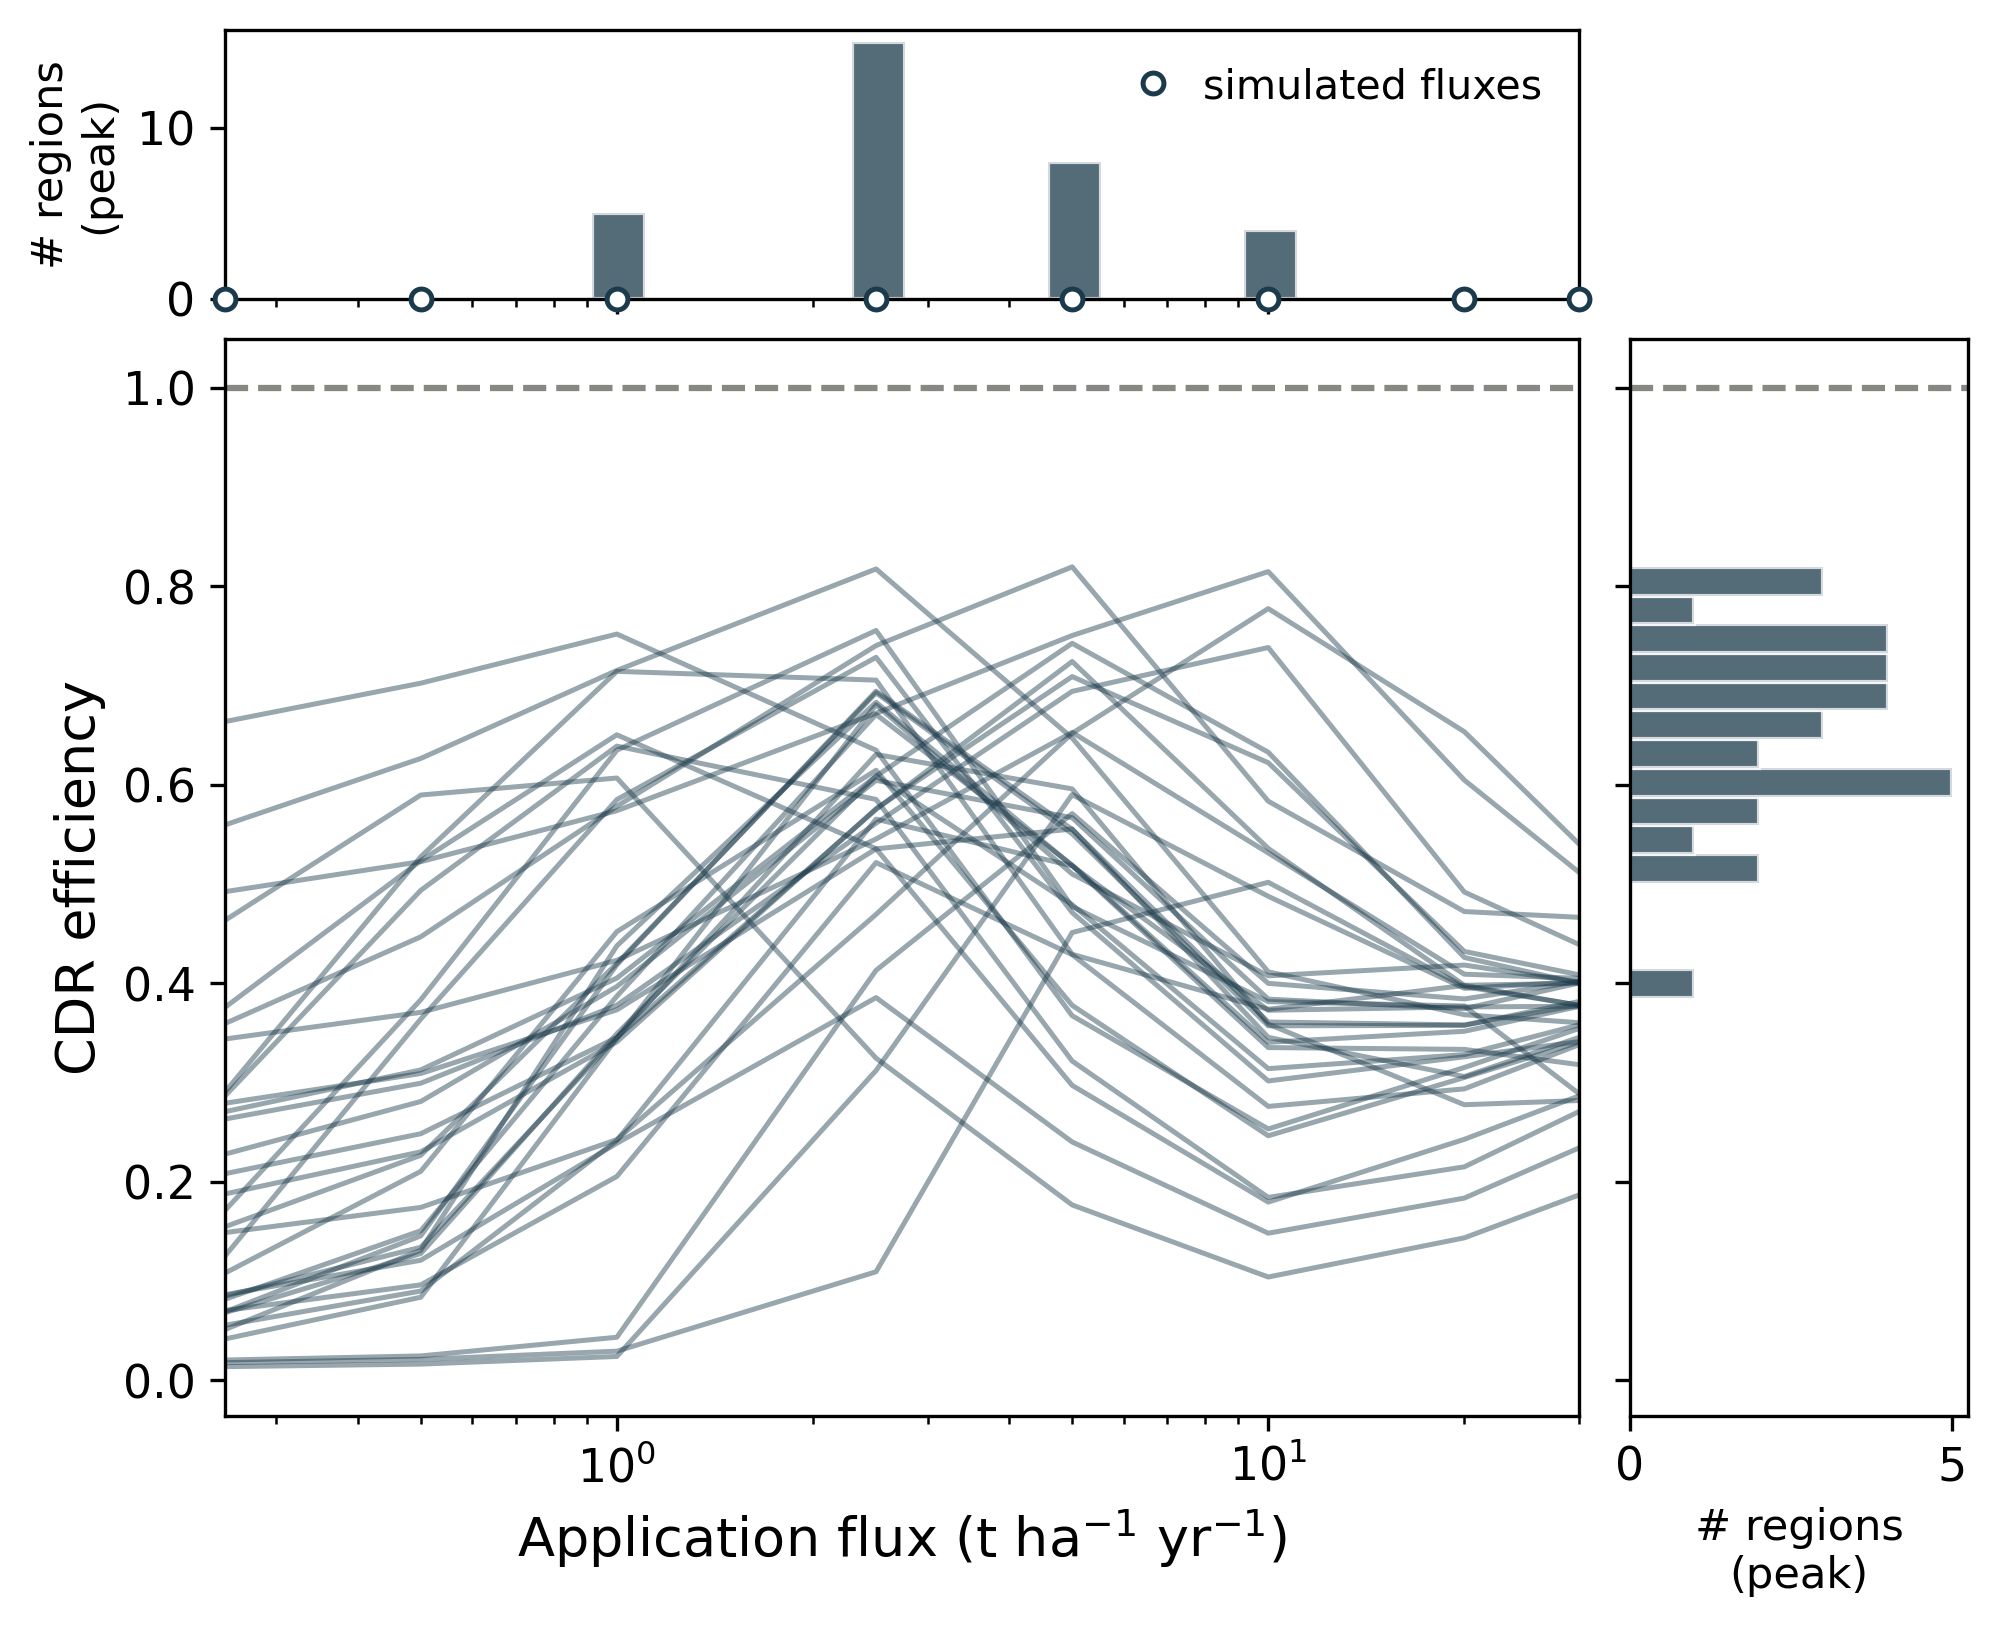

In [19]:
fig = plt.figure(figsize=(7.5, 6), dpi=300)
gs = fig.add_gridspec(2, 2, width_ratios=[4, 1], height_ratios=[1, 4], wspace=0.06, hspace=0.06)
ax      = fig.add_subplot(gs[1, 0])
ax_top  = fig.add_subplot(gs[0, 0], sharex=ax)
ax_side = fig.add_subplot(gs[1, 1], sharey=ax)

for a in (ax, ax_side):
    a.axhline(1.0, color=TARGET_COLOR, lw=1.5, ls="--", zorder=0)
for site in eff.site.values:
    ax.plot(eff.apprate_base, eff.sel(site=site), color=COLOR, lw=LW, alpha=ALPHA, zorder=2)

hist_kw = dict(color=COLOR, alpha=0.75, edgecolor="white")
# one bar per simulated apprate; open markers show every apprate that was run (the only possible peaks)
rates, counts = np.unique(peak_rate.values, return_counts=True)
ax_top.bar(rates * 10 ** (-TOP_BAR_DEX / 2), counts, width=rates * (10 ** TOP_BAR_DEX - 1), align="edge", **hist_kw)
ax_top.plot(eff.apprate_base, np.zeros(eff.apprate_base.size), "o", ms=5, mfc="white", mec=COLOR, mew=1.2,
            clip_on=False, zorder=3, label="simulated fluxes")
ax_top.legend(loc="upper right", frameon=False, fontsize=FS_TICK * 0.9, handletextpad=0.2)
ax_side.hist(peak_eff.values, bins=HIST_BINS, orientation="horizontal", **hist_kw)

ax.set_xscale("log")
ax.set_xlim(*XLIM)
if YLIM:
    ax.set_ylim(*YLIM)
ax.set_xlabel("Application flux (t ha$^{-1}$ yr$^{-1}$)", fontsize=FS_LAB)
ax.set_ylabel("CDR efficiency", fontsize=FS_LAB)
ax_top.set_ylabel("# regions\n(peak)", fontsize=FS_LAB * 0.8)
ax_side.set_xlabel("# regions\n(peak)", fontsize=FS_LAB * 0.8)
for a in (ax, ax_top, ax_side):
    a.tick_params(labelsize=FS_TICK)
plt.setp(ax_top.get_xticklabels(), visible=False)
plt.setp(ax_side.get_yticklabels(), visible=False)

plt.show()
if SAVE_ON:
    fig.savefig(os.path.join(savehere, "cecSicLim-allRegions.png"), dpi=300, bbox_inches="tight")

## Global CDR efficiency by grain size

The top panel of `fig-cecSicLimits` for different grain sizes.

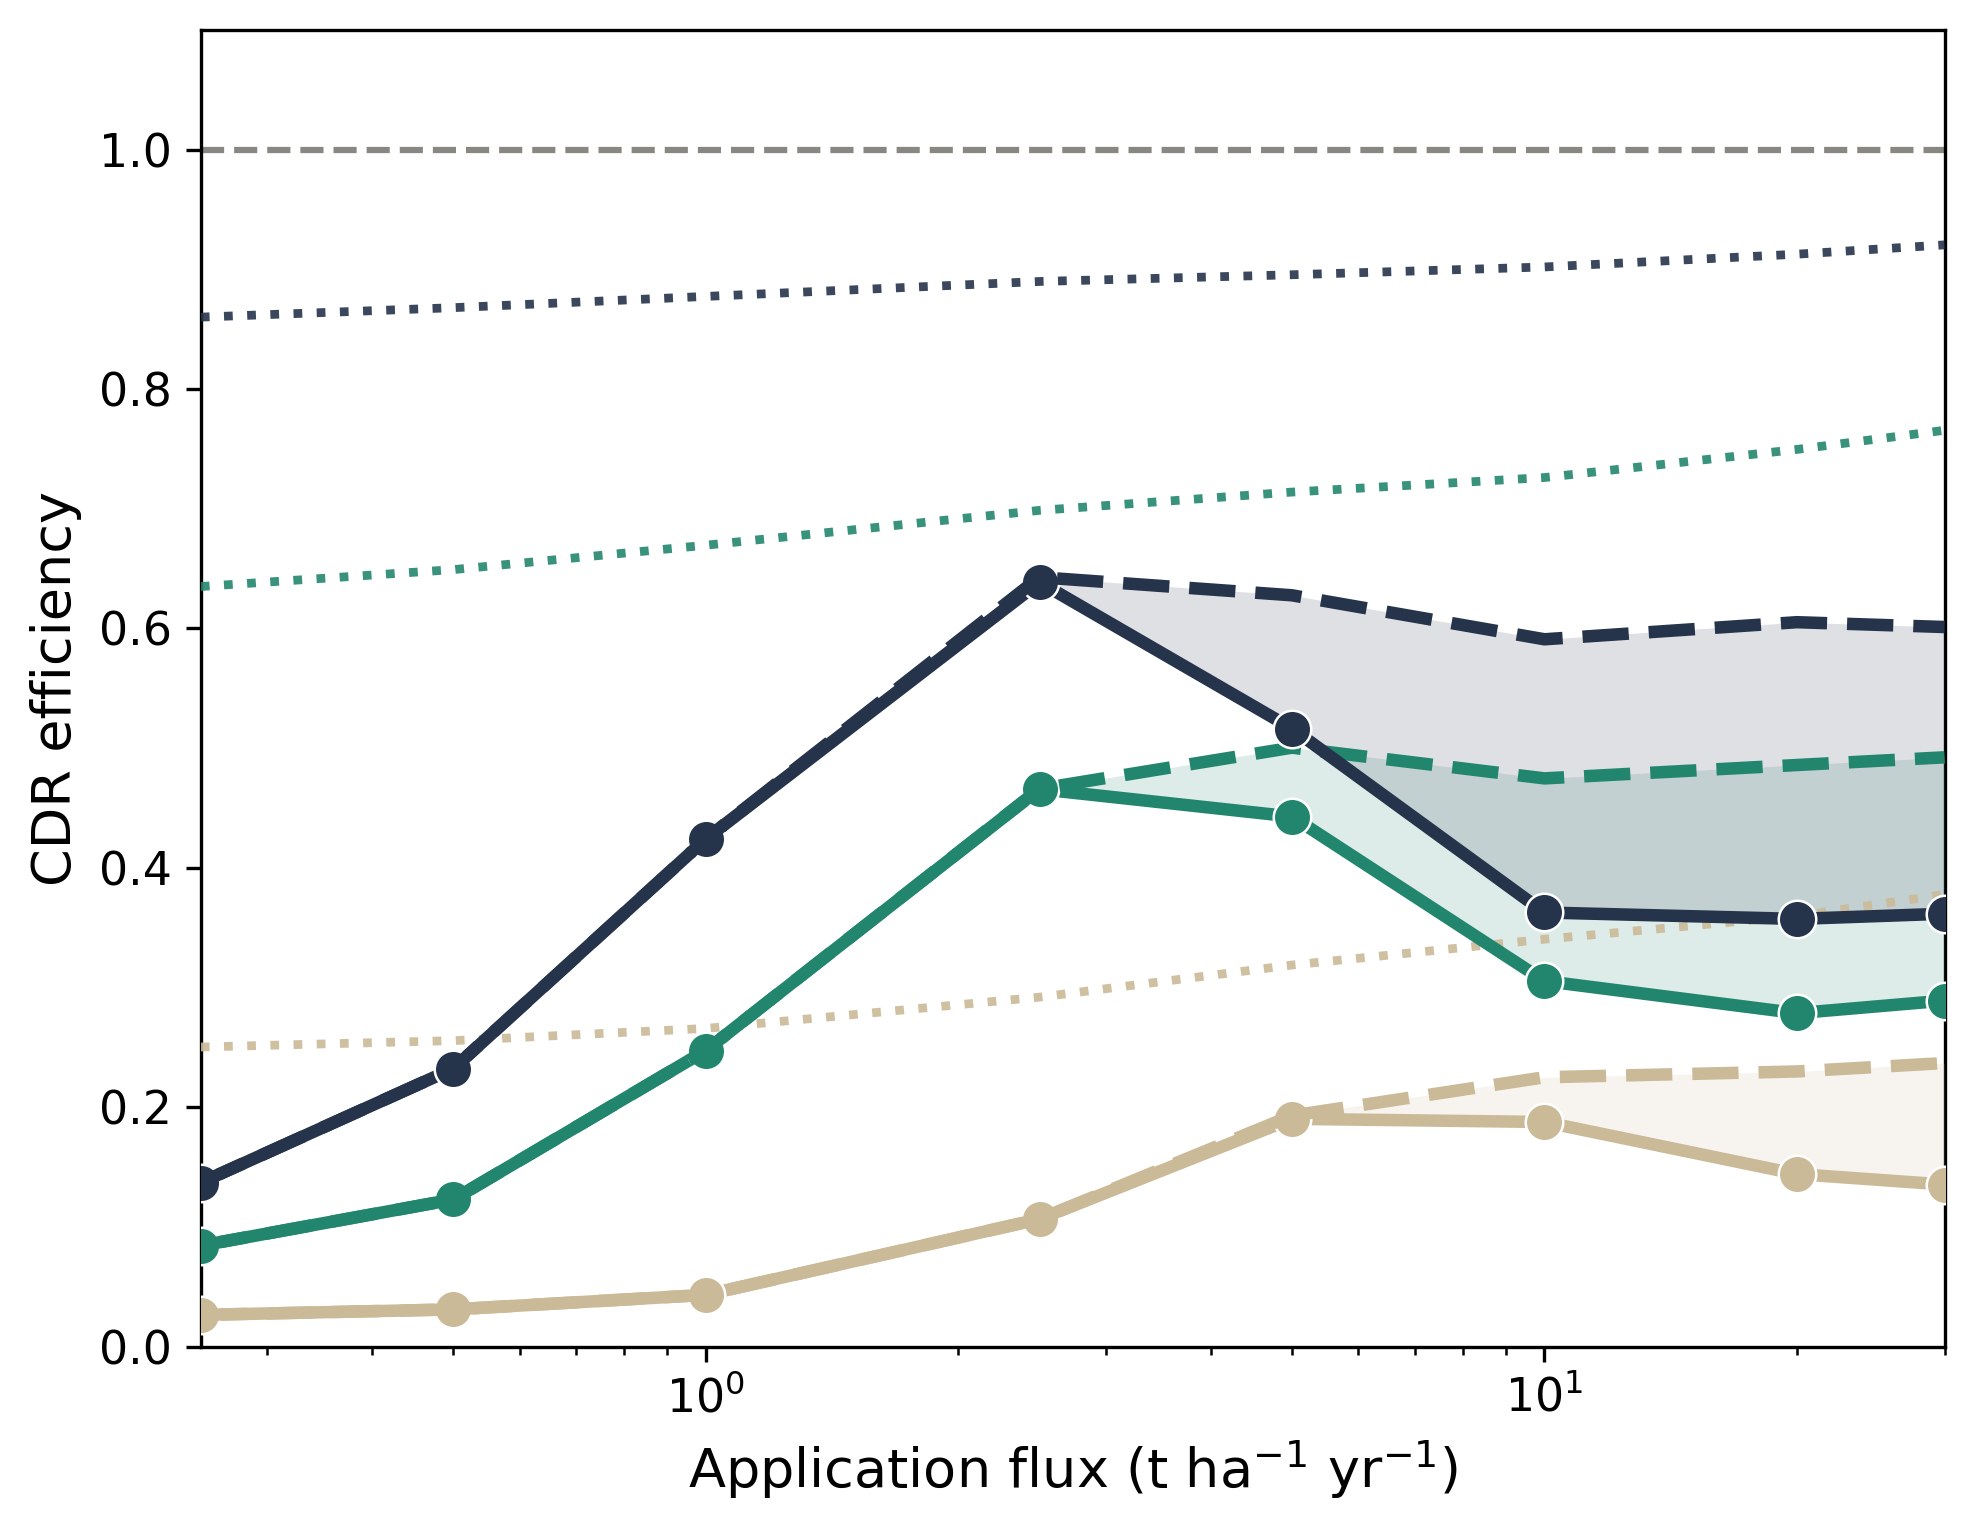

In [21]:
import cmocean

DUSTRADS      = [0.2, 1, 5]    # finest first; any of dssum.dustrad.values
SHOW_DISS_POT = True
DISS_CO2_PER_T = 0.3           # t CO2 per t rock dissolved
PALETTE       = [cmocean.cm.rain_r(x) for x in np.linspace(0.1, 0.8, len(DUSTRADS))]

sel = dict(cec_factor=CEC_FACTOR, apprate_base=slice(APPRATE_MIN, APPRATE_MAX))
glob = lambda v: dssum[v].sel(dustrad=DUSTRADS, **sel).sum(["site", "time"]).compute()
target = float(dssum["gcam_cdr_globe"].sel(dustrad=DUSTRADS[0], **sel).sum("time").mean("apprate_base"))
adv  = glob("cdr_adv_region") / target
tot  = adv + glob("cdr_SIConly_region") / target
diss = glob("total_dissolution_region") * DISS_CO2_PER_T / target

fig, ax = plt.subplots(figsize=(7.5, 5.7), dpi=300)
ax.axhline(1.0, color=TARGET_COLOR, lw=1.5, ls="--", zorder=0)
for i, dr in enumerate(DUSTRADS):
    c, z, x = PALETTE[i], 20 - i, adv.apprate_base   # finest on top
    ax.fill_between(x, adv.sel(dustrad=dr), tot.sel(dustrad=dr), color=c, alpha=0.15, lw=0, zorder=10 - i)
    ax.plot(x, adv.sel(dustrad=dr), color=c, lw=3, marker="o", ms=9, mec="white", mew=0.6,
            solid_capstyle="round", label=f"{dr:g}", zorder=z)
    ax.plot(x, tot.sel(dustrad=dr), color=c, lw=3, ls="--", zorder=z)
    if SHOW_DISS_POT:
        ax.plot(x, diss.sel(dustrad=dr), color=c, lw=2.1, ls=":", alpha=0.9, zorder=z)

ax.set_xscale("log")
ax.set_xlim(*XLIM)
ax.set_ylim(0, 1.1)
ax.set_xlabel("Application flux (t ha$^{-1}$ yr$^{-1}$)", fontsize=FS_LAB)
ax.set_ylabel("CDR efficiency", fontsize=FS_LAB)
ax.tick_params(labelsize=FS_TICK)
# ax.legend(title="Dust radius (μm)", fontsize=FS_TICK, title_fontsize=FS_TICK, frameon=False,
#           ncol=len(DUSTRADS), loc="center left", bbox_to_anchor=(0.01, 0.69), columnspacing=1.2)

plt.show()
if SAVE_ON:
    fig.savefig(os.path.join(savehere, "cecSicLim-byDustrad.png"), dpi=300, bbox_inches="tight")

In [ ]:
# ---